# MY OWN TEMPLATE: MLP, CNN, LSTM and GRU on Silver (5-minute Bid and Ask)

**Idea:** every model uses the **same data pipeline**. Only the **model block** is different. So this notebook has:

| Part | What it is | Same for every model? |
|---|---|---|
| A | Settings (all numbers in one cell) | yes, you edit the numbers |
| B | Data functions (merge, features, normalise, answers, windows, split) | **yes** |
| C | Model functions (MLP, CNN, LSTM, GRU) | **no, this is the only part that differs** |
| D | Train, test and chart functions | **yes** |
| E | Run one model | you choose the model |

**Make it yours:** rename the functions and variables, change the comments to your own words, and retype the code once. You will understand it better and it will not look like anyone else's notebook.

## Part A: Imports and settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow import keras

np.random.seed(19)

In [2]:
ASK_FILE = 'XAGUSD_5 Mins_Ask_2023.01.01_2023.06.30-1.csv'   # CHANGE: the Ask file name
BID_FILE = 'XAGUSD_5 Mins_Bid_2023.01.01_2023.06.30-1.csv'   # CHANGE: the Bid file name

N = 50              # how many rows each window looks back
HORIZON = 5         # predict the highest High_Bid and lowest Low_Ask over the next HORIZON rows
N_SMALL = 30000     # how many rows are used to build the windows
NORM_SHARE = 0.8    # share of rows used to calculate the min and max for normalising
TEST_SIZE = 0.1     # share of windows kept for testing

EPOCHS = 10
BATCH = 20
PATIENCE = 5        # early stopping patience
VAL_SPLIT = 0.1     # share of the training windows used for validation

## Part B: Data functions (the same for every model)
**What you can change:** nothing here. Change the numbers in Part A instead. If the test gives other column names, change them in `load_and_merge` only.

In [3]:
def load_and_merge(ask_file, bid_file):
    ask = pd.read_csv(ask_file)
    bid = pd.read_csv(bid_file)
    both = bid.merge(ask, on='Time (UTC)', how='outer')
    both.columns = ['time', 'Open_Bid', 'High_Bid', 'Low_Bid', 'Close_Bid', 'Volume_Bid',
                    'Open_Ask', 'High_Ask', 'Low_Ask', 'Close_Ask', 'Volume_Ask']
    return both


def add_features(df):
    df = df.copy()
    df['Volume_Delta'] = df['Volume_Ask'] - df['Volume_Bid']
    df['Volume_Delta_abs'] = df['Volume_Delta'].abs()
    for p in ['Open', 'High', 'Low', 'Close']:
        df[p + '_Delta'] = df[p + '_Ask'] - df[p + '_Bid']
    df['Y_High_Bid'] = df['High_Bid']
    df['Y_Low_Ask'] = df['Low_Ask']
    return df


def mark_days_and_weeks(df):
    df = df.copy()
    gap = pd.to_datetime(df['time'], utc=True).diff()
    normal_gap = gap.mode()[0]                       # the usual gap between rows (5 minutes here)
    df['New_day'] = (gap > normal_gap).astype(int)
    df['New_week'] = (gap > pd.Timedelta(days=1)).astype(int)
    df.loc[df.index[0], ['New_day', 'New_week']] = 1  # the first row starts a day and a week
    return df.drop(columns=['time'])


def normalise(df, share):
    df = df.copy()
    n_train = int(round(len(df) * share, -3))
    tr = df.iloc[:n_train]                            # min and max come from the training part only
    deltas = ['Open_Delta', 'High_Delta', 'Low_Delta', 'Close_Delta']

    price_min = tr['Low_Bid'].min()
    price_max = (tr['High_Bid'] + tr['High_Delta']).max()
    volume_max = max(tr['Volume_Bid'].max(), tr['Volume_Ask'].max())
    delta_max = round(tr[deltas].max().max(), 3)
    delta_min = round(tr[deltas].min().min(), 3)
    vdelta_min, vdelta_max = tr['Volume_Delta'].min(), tr['Volume_Delta'].max()
    vdelta_abs_max = tr['Volume_Delta_abs'].max()

    for c in ['Open_Bid', 'High_Bid', 'Low_Bid', 'Close_Bid', 'Y_High_Bid', 'Y_Low_Ask']:
        df[c] = (df[c] - price_min) / (price_max - price_min)
    df['Volume_Ask'] = df['Volume_Ask'] / volume_max
    df['Volume_Bid'] = df['Volume_Bid'] / volume_max
    df['Volume_Delta'] = (df['Volume_Delta'] - vdelta_min) / (vdelta_max - vdelta_min)
    df['Volume_Delta_abs'] = df['Volume_Delta_abs'] / vdelta_abs_max
    for c in deltas:
        df[c] = (delta_max - df[c]) / (delta_max - delta_min)    # small spread becomes close to 1

    order = ['Open_Bid', 'High_Bid', 'Low_Bid', 'Close_Bid', 'Volume_Bid', 'Volume_Ask',
             'Volume_Delta', 'Volume_Delta_abs', 'Open_Delta', 'High_Delta', 'Low_Delta', 'Close_Delta',
             'New_day', 'New_week', 'Y_High_Bid', 'Y_Low_Ask']
    return df[order], {'price_min': price_min, 'price_max': price_max}


def make_answers(df, horizon):
    ans = df[['Y_High_Bid', 'Y_Low_Ask']].shift(-1)
    window = pd.api.indexers.FixedForwardWindowIndexer(window_size=horizon)
    high = ans['Y_High_Bid'].rolling(window=window).max()
    low = ans['Y_Low_Ask'].rolling(window=window).min()
    y = pd.concat([high, low], axis=1).iloc[:-horizon]          # drop the last rows that have no answer
    x = df.drop(columns=['Y_High_Bid', 'Y_Low_Ask']).iloc[:-horizon]
    return x.to_numpy(), y.to_numpy()


def make_windows(x, y, n, n_small):
    count = n_small - n
    X = np.array([x[k:k + n] for k in range(count)], dtype='float32')
    Y = np.array([y[k + n - 1] for k in range(count)], dtype='float32')
    return X, Y


def prepare_data():
    df = load_and_merge(ASK_FILE, BID_FILE)
    df = add_features(df)
    df = mark_days_and_weeks(df)
    df, scale = normalise(df, NORM_SHARE)
    x, y = make_answers(df, HORIZON)
    X, Y = make_windows(x, y, N, N_SMALL)
    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=TEST_SIZE, shuffle=False)
    return X_train, X_test, y_train, y_test, scale

In [4]:
X_train, X_test, y_train, y_test, scale = prepare_data()

print('X_train', X_train.shape)    # expected (26955, 50, 14)
print('y_train', y_train.shape)    # expected (26955, 2)
print('X_test ', X_test.shape)     # expected (2995, 50, 14)
print('y_test ', y_test.shape)     # expected (2995, 2)

STEPS = X_train.shape[1]           # rows per window
FEATS = X_train.shape[2]           # input columns (14)
OUTS = y_train.shape[1]            # answers (2)

X_train (26955, 50, 14)
y_train (26955, 2)
X_test  (2995, 50, 14)
y_test  (2995, 2)


## Part C: Model functions (the only part that is different)
Every model gets the same input `(STEPS, FEATS)` and gives the same output `OUTS`.

| Model | Idea | Expected `summary()` total for (50, 14) |
|---|---|---|
| MLP | `Flatten` turns the window into one long row, then normal `Dense` layers | 212,610 |
| CNN | `Conv1D` filters slide along the 50 rows | 44,027 |
| LSTM | reads the 50 rows in order and keeps a memory | 46,202 |
| GRU | like LSTM with a simpler memory | 35,002 |

**What you can change:** the numbers inside each function (units, filters, kernel sizes, layers). The Input line and the last `Dense(OUTS)` line stay.

In [5]:
def mlp_model(units1=256, units2=128):
    return keras.Sequential([
        keras.layers.Input(shape=(STEPS, FEATS)),
        keras.layers.Flatten(),
        keras.layers.Dense(units1, activation='relu'),
        keras.layers.Dense(units2, activation='relu'),
        keras.layers.Dense(OUTS)
    ])


#def cnn_model(filters1=50, kernel1=9, filters2=100, kernel2=7, pool=7, dense=25):
 #   return keras.Sequential([
    #    keras.layers.Input(shape=(STEPS, FEATS)),
    #    keras.layers.Conv1D(filters1, kernel1, padding='same', activation='relu'),
      #  keras.layers.MaxPooling1D(pool),
      #  keras.layers.Conv1D(filters2, kernel2, padding='same', activation='relu'),
     #   keras.layers.GlobalMaxPooling1D(),
     #   keras.layers.Dense(dense, activation='relu'),
     #   keras.layers.Dense(OUTS)
   # ])


#def lstm_model(units=100):
    #return keras.Sequential([
     #   keras.layers.Input(shape=(STEPS, FEATS)),
     #   keras.layers.LSTM(units, activation='relu'),
      #  keras.layers.Dense(OUTS)
    #])


#def gru_model(units=100):
    #return keras.Sequential([
       # keras.layers.Input(shape=(STEPS, FEATS)),
       # keras.layers.GRU(units, activation='relu'),
       # keras.layers.Dense(OUTS)
    #])

## Part D: Train, test and chart functions (the same for every model)
**What you can change:** `EPOCHS`, `BATCH`, `PATIENCE` and `VAL_SPLIT` in Part A. The file name is built from the model name, so each model saves its own best version and never overwrites another.

In [6]:
def train_and_test(model, name):
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=PATIENCE, verbose=1)
    save = keras.callbacks.ModelCheckpoint('best_' + name + '.keras', monitor='val_loss', mode='min',
                                           save_best_only=True, verbose=1)
    hist = model.fit(X_train, y_train, batch_size=BATCH, epochs=EPOCHS,
                     validation_split=VAL_SPLIT, shuffle=True, callbacks=[stop, save], verbose=1)
    best = keras.models.load_model('best_' + name + '.keras')      # the best epoch, not the last one
    mse, mae = best.evaluate(X_test, y_test, verbose=0)
    print(name, 'test MSE: %.9f' % mse)
    print(name, 'test MAE: %.9f' % mae)
    return best, hist, mse, mae


def mae_graph(hist, name):
    mae = hist.history['mae']
    val_mae = hist.history['val_mae']
    epochs = range(1, len(mae) + 1)
    plt.figure(figsize=(15, 7))
    plt.plot(epochs, mae, 'b', label='Training Mean Absolute Error (MAE)')
    plt.plot(epochs, val_mae, marker='o', markeredgecolor='green', markerfacecolor='yellow',
             label='Validation Mean Absolute Error (MAE)')
    plt.title(name + ': MAE during training', size=20)
    plt.xlabel('Epochs', size=18)
    plt.ylabel('Mean Absolute Error (MAE)', size=18)
    plt.legend()
    plt.show()


def price_charts(best, name, first=2500, length=500):
    pred = best.predict(X_test, verbose=0)
    last = first + length
    plt.figure(figsize=(15, 7))
    plt.plot(y_test[first:last, 0], label='High_Bid')
    plt.plot(pred[first:last, 0], label='Predicted High_Bid')
    plt.plot(y_test[first:last, 1], label='Low_Ask')
    plt.plot(pred[first:last, 1], label='Predicted Low_Ask')
    plt.title(name + ': Real and predicted prices (normalised)', size=22)
    plt.xlabel('Rows', size=18)
    plt.ylabel('Normalised SILVER prices', size=18)
    plt.legend(loc='upper right')
    plt.show()

    to_dollars = scale['price_max'] - scale['price_min']        # turns normalised errors into dollars
    plt.figure(figsize=(15, 7))
    plt.plot((pred[:1500, 0] - y_test[:1500, 0]) * to_dollars, label='Predicted High_Bid error')
    plt.plot((pred[:1500, 1] - y_test[:1500, 1]) * to_dollars, label='Predicted Low_Ask error')
    plt.title(name + ': Error chart', size=22)
    plt.xlabel('Rows', size=18)
    plt.ylabel('Error in $', size=18)
    plt.legend(loc='upper right')
    plt.show()

## Part E: Run ONE model
To use another model, change **two things**: the model function and the name.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 700)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       179,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,610 (830.51 KB)

 Trainable params: 212,610 (830.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1213/1213 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0039 - mae: 0.0225
Epoch 1: val_loss improved from None to 0.00025, saving model to best_MLP.keras

Epoch 1: finished saving model to best_MLP.keras
1213/1213 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - loss: 0.0039 - mae: 0.0225 - val_loss: 2.4531e-04 - val_mae: 0.0117
Epoch 2/10
1208/1213 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3.2652e-04 - mae: 0.0137
Epoch 2: val_loss did not improve from 0.00025
1213/1213 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - loss: 3.2659e-04 - mae: 0.0137 - val_loss: 3.2945e-04 - val_mae: 0.0152
Epoch 3/10
1211/1213 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.7488e-04 - mae: 0.0126
Epoch 3: val_loss improved from 0.00025 to 0.00011, saving model to best_MLP.keras

Epoch 3: finished saving model to best_MLP.keras
1213/1213 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - loss: 2.7479e-04 - mae: 0.0126 - val_loss: 1.0872e-04 - val_mae: 0.0073
Epoch 4/10
1213/1213 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.3230e-04 - mae: 0.011

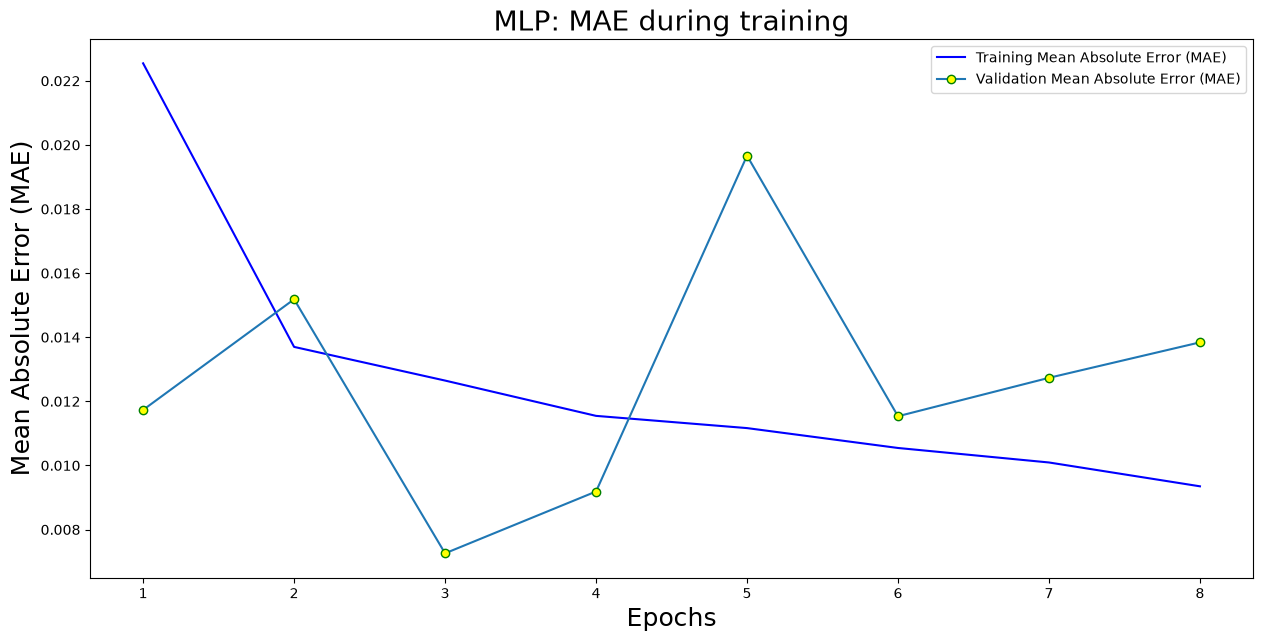

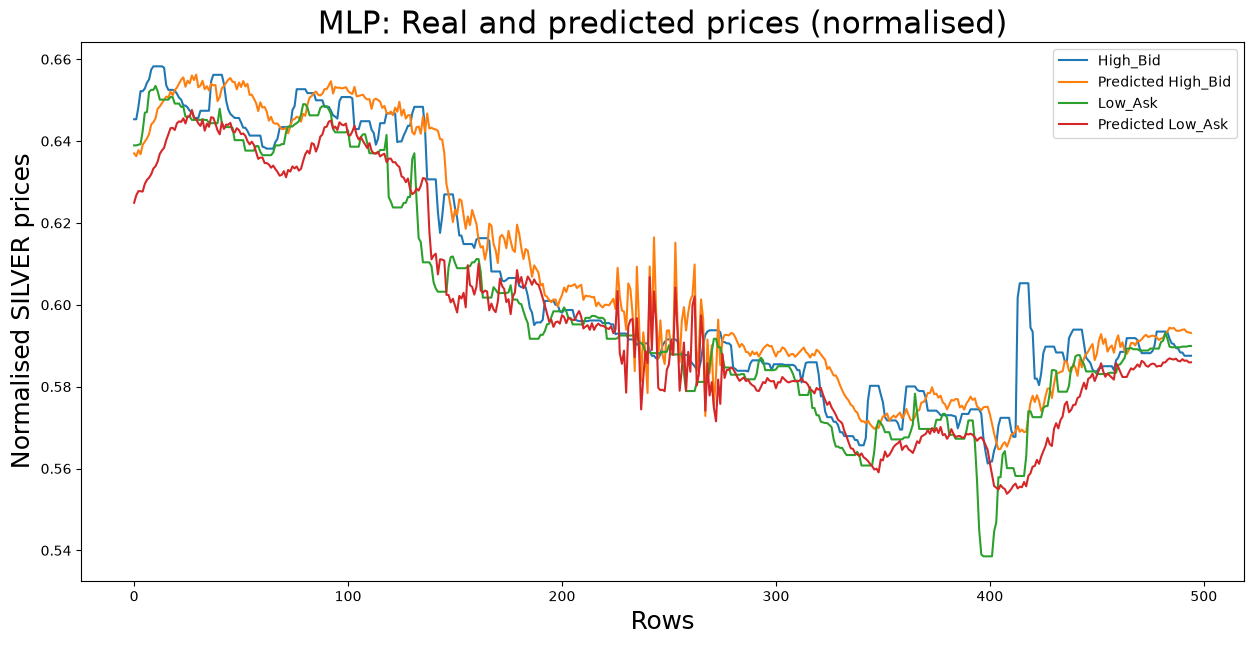

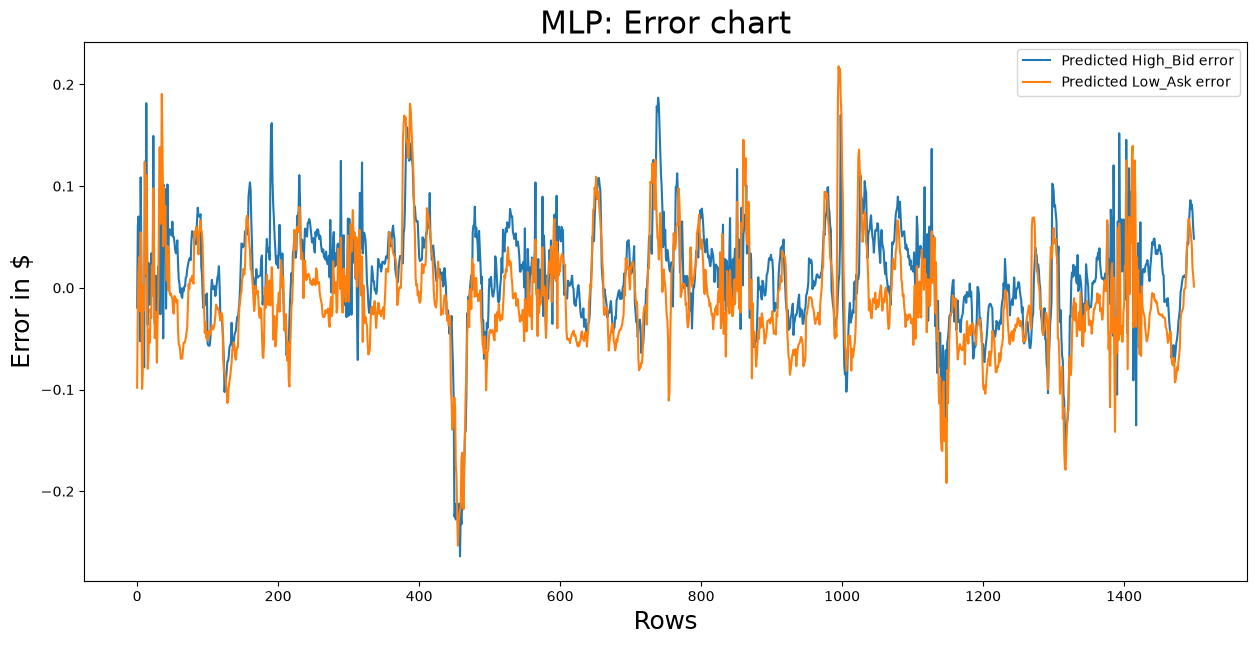

In [7]:
model = mlp_model()          # CHANGE: mlp_model(), cnn_model(), lstm_model() or gru_model()
NAME = 'MLP'                 # CHANGE: the same model name, in capitals

model.summary()
best, hist, mse, mae = train_and_test(model, NAME)
mae_graph(hist, NAME)
price_charts(best, NAME)

**Optional: compare all four models** (takes much longer, so do not run it in the test unless asked).

In [ ]:
results = {}
for name, make in [('MLP', mlp_model), ('CNN', cnn_model), ('LSTM', lstm_model), ('GRU', gru_model)]:
    best, hist, mse, mae = train_and_test(make(), name)
    results[name] = [mse, mae]

print(pd.DataFrame(results, index=['MSE', 'MAE']).T)

## What to change in the test (quick guide)

| The question says | You change |
|---|---|
| Other file names | `ASK_FILE`, `BID_FILE` |
| Predict the next 10 rows instead of 5 | `HORIZON = 10` (nothing else) |
| Look back 30 rows | `N = 30` (the model reads `STEPS` automatically) |
| Use 20,000 rows | `N_SMALL = 20000` |
| 80/20 split for testing | `TEST_SIZE = 0.2` |
| 100 → 64 units | `lstm_model(64)` |
| Epochs 8, patience 3, batch 40 | `EPOCHS = 8`, `PATIENCE = 3`, `BATCH = 40` |
| Another model | `model = cnn_model()` and `NAME = 'CNN'` |
| Two LSTM layers | in `lstm_model` replace the LSTM line with the two lines below |
| MSE graph instead of MAE | in `mae_graph` use `hist.history['loss']` and `['val_loss']` |

```python
        keras.layers.LSTM(units, activation='relu', return_sequences=True),
        keras.layers.LSTM(units2, activation='relu'),
```
(Add `units2=50` to the function line. Only the **first** LSTM needs `return_sequences=True`.)

**Compared with the lecturer's notebooks:** the answers and the end of the table are cut with `iloc[:-HORIZON]` instead of the delete-last-rows loops, so there is **no cell that must be run only once**. The normal gap between rows is found automatically with `gap.mode()`, so the day and week markers work for 1-minute, 5-minute or 15-minute data.